In [1]:
import torch
from torch import nn

In [2]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [3]:
import requests
import zipfile
from pathlib import Path

data_path=Path("data/")
image_path=data_path/"pizza_steak_sushi"

if image_path.is_dir():
    print(f"{image_path} directory already exists... skipping download")
else:
    print(f"{image_path} does not exist,creating one...")
    image_path.mkdir(parents=True,exist_ok=True)

with open(data_path/"pizza_steak_sushi.zip","wb") as f:
    request=requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print("Downloading .....")
    f.write(request.content)

with zipfile.ZipFile(data_path/"pizza_steak_sushi.zip","r") as zip_ref:
    print("UNzipping .....")
    zip_ref.extractall(image_path)

data/pizza_steak_sushi directory already exists... skipping download
UNzipping .....


In [4]:
import os

def walk_through_dir(dir_path):
    """Walks through"""
    for dirpath,dirnames,filename in os.walk(dir_path):
        print(f"There are {len(dirnames)} directory and {len(filename)} images in '{dirpath}'.")

In [5]:
walk_through_dir(image_path)

There are 2 directory and 0 images in 'data/pizza_steak_sushi'.
There are 3 directory and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directory and 72 images in 'data/pizza_steak_sushi/train/sushi'.
There are 0 directory and 78 images in 'data/pizza_steak_sushi/train/pizza'.
There are 0 directory and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 3 directory and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directory and 31 images in 'data/pizza_steak_sushi/test/sushi'.
There are 0 directory and 25 images in 'data/pizza_steak_sushi/test/pizza'.
There are 0 directory and 19 images in 'data/pizza_steak_sushi/test/steak'.


In [6]:
train_dir=image_path/"train"
test_dir=image_path/"test"

train_dir,test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [7]:
import random
from PIL import Image

# random.seed(42)


image_path_list=list(image_path.glob("*/*/*.jpg"))

image_path_list

[PosixPath('data/pizza_steak_sushi/train/sushi/1232045.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1214108.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/390178.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2019344.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/855721.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2813454.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2492146.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1280119.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1615453.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1551817.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/773725.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2641778.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/121940.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/3360232.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/3251688.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1209865.jpg'),
 PosixPath('

In [8]:
len(image_path_list)

300

Random image path: data/pizza_steak_sushi/test/pizza/3092704.jpg
Image class: pizza
Image height: 512
Image: 512


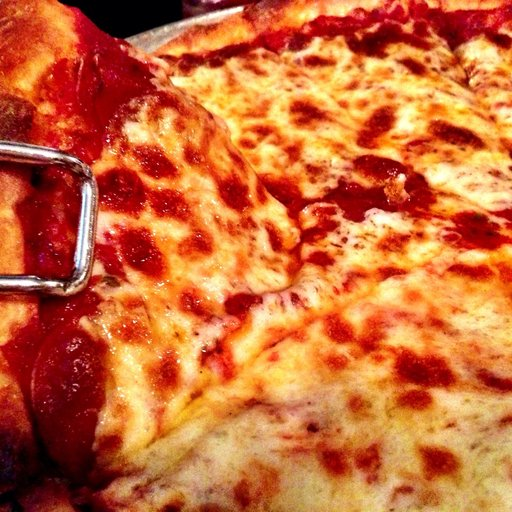

In [9]:
random_image_path=random.choice(image_path_list)

image_class=random_image_path.parent.stem

img=Image.open(random_image_path)

print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image: {img.width}")
img

In [10]:
import numpy as np
import matplotlib.pyplot as plt

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

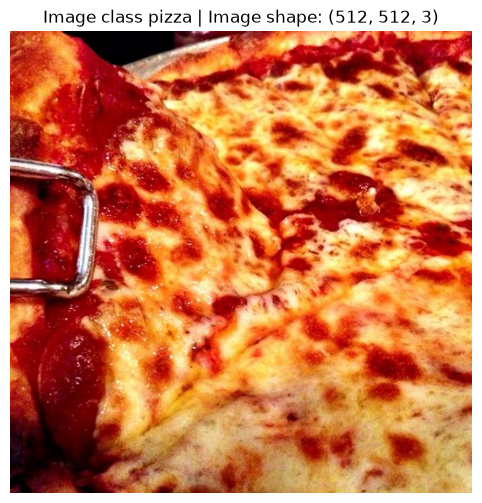

In [11]:
image_as_array=np.asarray(img)

plt.figure(figsize=(10,6))
plt.imshow(image_as_array)
plt.title(f"Image class {image_class} | Image shape: {image_as_array.shape}")
plt.axis(False)

In [12]:
image_as_array

array([[[201,  96,  75],
        [181,  75,  53],
        [170,  55,  36],
        ...,
        [217,  45,  35],
        [230,  54,  41],
        [213,  37,  22]],

       [[220, 113,  95],
        [179,  70,  50],
        [169,  54,  35],
        ...,
        [211,  37,  30],
        [214,  37,  27],
        [201,  25,  12]],

       [[192,  82,  67],
        [154,  41,  25],
        [167,  50,  33],
        ...,
        [234,  59,  56],
        [217,  39,  35],
        [195,  18,  12]],

       ...,

       [[ 84,  10,  11],
        [ 93,  21,  22],
        [102,  30,  33],
        ...,
        [231, 199, 140],
        [225, 193, 136],
        [227, 196, 141]],

       [[ 84,   4,   5],
        [ 87,   9,   9],
        [ 92,  16,  18],
        ...,
        [231, 199, 140],
        [227, 195, 138],
        [228, 195, 141]],

       [[ 90,   8,  10],
        [ 81,   1,   2],
        [ 80,   0,   3],
        ...,
        [233, 198, 140],
        [230, 198, 141],
        [231, 198, 144]]

In [13]:
import torch 
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

In [14]:
data_trasnform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

In [15]:
data_trasnform(img).shape

torch.Size([3, 64, 64])

In [16]:
data_trasnform(img)

tensor([[[0.6941, 0.7765, 0.8196,  ..., 0.9647, 0.9216, 0.8078],
         [0.7255, 0.7843, 0.8510,  ..., 0.8549, 0.8431, 0.7098],
         [0.7137, 0.7373, 0.7529,  ..., 0.8980, 0.8549, 0.7922],
         ...,
         [0.1059, 0.0588, 0.0706,  ..., 0.8353, 0.8745, 0.8980],
         [0.0392, 0.0353, 0.1216,  ..., 0.8392, 0.8706, 0.9137],
         [0.2235, 0.0980, 0.0824,  ..., 0.8431, 0.8745, 0.8980]],

        [[0.1804, 0.2471, 0.3020,  ..., 0.5804, 0.3647, 0.1412],
         [0.1922, 0.2941, 0.3961,  ..., 0.2196, 0.1333, 0.0431],
         [0.2235, 0.2314, 0.2118,  ..., 0.2353, 0.1216, 0.1176],
         ...,
         [0.0078, 0.0039, 0.0039,  ..., 0.7098, 0.7686, 0.7961],
         [0.0039, 0.0039, 0.0078,  ..., 0.6706, 0.7216, 0.8078],
         [0.0314, 0.0196, 0.0078,  ..., 0.6706, 0.7216, 0.7804]],

        [[0.0980, 0.1294, 0.1216,  ..., 0.2980, 0.2000, 0.1255],
         [0.0863, 0.1176, 0.1725,  ..., 0.1490, 0.1490, 0.0902],
         [0.1333, 0.1176, 0.1059,  ..., 0.1882, 0.1529, 0.

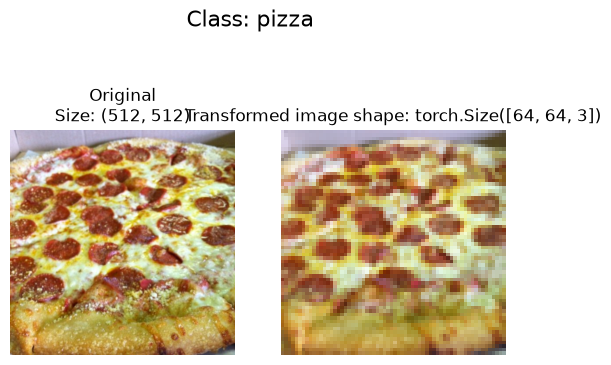

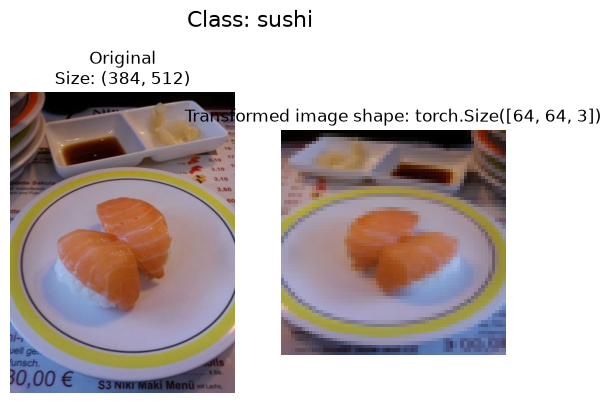

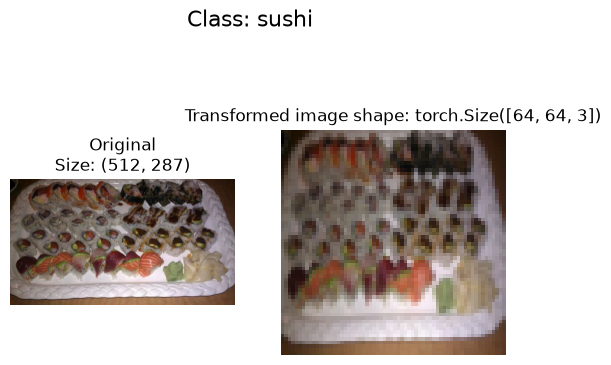

In [17]:
def plot_transformed_images(image_paths,transform,n=3,seed=42):
    if seed:
        random.seed(seed)

    random_image_paths=random.sample(image_paths,k=n)

    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig,ax=plt.subplots(nrows=1,ncols=2)

            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)

            transformed_image=transform(f).permute(1,2,0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed image shape: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}",fontsize=16)
plot_transformed_images(image_paths=image_path_list,transform=data_trasnform,n=3,seed=None)

In [18]:
from torchvision import datasets

train_data=datasets.ImageFolder(root=train_dir,
                                transform=data_trasnform,
                                target_transform=None)

test_data=datasets.ImageFolder(root=test_dir,transform=data_trasnform)

train_data,test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [19]:
class_names=train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [20]:
class_dict=train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [21]:
len(train_data),len(test_data)

(225, 75)

In [22]:
train_data.samples[0]

('data/pizza_steak_sushi/train/pizza/1008844.jpg', 0)

In [23]:
img,label=train_data[0][0],train_data[0][1]
print(f"Image tensor:\n {img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image Label: {label}")
print(f"Label Datatype: {type(label)}")

Image tensor:
 tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.0

In [24]:
img_premute=img.permute(1,2,0)

print(img_premute.shape)

torch.Size([64, 64, 3])


In [25]:
import os
os.cpu_count()

12

In [26]:
from torch.utils.data import DataLoader

BATCH_SIZE=1

train_dataloader=DataLoader(dataset=train_data,batch_size=BATCH_SIZE,num_workers=1,shuffle=True)
test_dataloader=DataLoader(dataset=test_data,batch_size=BATCH_SIZE,num_workers=1,shuffle=False)

train_dataloader,test_dataloader


(<torch.utils.data.dataloader.DataLoader at 0x7de25b6cd430>,
 <torch.utils.data.dataloader.DataLoader at 0x7de25b7da270>)

In [27]:
len(train_dataloader),len(test_dataloader)

(225, 75)

In [28]:
img,label=next(iter(train_dataloader))
print(f"Image: {img.shape} -> [batch_size,color_channels,height,weidth]")
print(f"Label shape: {label.shape}")

Image: torch.Size([1, 3, 64, 64]) -> [batch_size,color_channels,height,weidth]
Label shape: torch.Size([1])


In [29]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset

from torchvision import transforms
from typing import Tuple,Dict,List

In [30]:
train_data.classes,train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [31]:
target_directory=train_dir

print(f"Target dir: {target_directory}")

class_names_found=sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target dir: data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [32]:
list(os.scandir(target_directory))

[<DirEntry 'sushi'>, <DirEntry 'pizza'>, <DirEntry 'steak'>]

In [33]:
def find_classes(directory: str) -> Tuple[List[str],Dict[str,int]]:
    classes=sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}... please check file structurre=e")

    class_to_idx={class_name: i for i,class_name in enumerate(classes)}
    return classes,class_to_idx

In [34]:
find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [35]:
from torch.utils.data import Dataset

class ImageFolderCustom(Dataset):
    def __init__(self,targ_dir:str,transform=None):
        self.paths=list(pathlib.Path(targ_dir).glob("*/*.jpg"))


        self.transform=transform

        self.classes,self.class_to_idx=find_classes(targ_dir)

    def load_image(self,index: int)->Image.Image:
        image_path=self.paths[index]
        return Image.open(image_path)

    def __len__(self)->int:
        return len(self.paths)

    def __getitem__(self,index:int)->Tuple[torch.Tensor,int]:
        img=self.load_image(index)
        class_name=self.paths[index].parent.name
        class_idx=self.class_to_idx[class_name]

        if self.transform:
            return self.transform(img),class_idx
        else:
            return img,class_idx

    

In [36]:
from torchvision import transforms

train_transforms=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transforms=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

In [37]:
train_data_custom=ImageFolderCustom(train_dir,train_transforms)
test_data_custom=ImageFolderCustom(test_dir,test_transforms)

In [38]:
train_data_custom,test_data_custom

(<__main__.ImageFolderCustom at 0x7de25b556f30>,
 <__main__.ImageFolderCustom at 0x7de25b545a60>)

In [39]:
len(test_data),len(test_data_custom)

(75, 75)

In [40]:
len(train_data),len(train_data_custom)

(225, 225)

In [41]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [42]:
train_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [43]:
print(train_data_custom.classes==train_data.classes)
print(test_data_custom.classes==test_data.classes)

True
True


In [44]:
import torch
import random
import matplotlib.pyplot as plt
from typing import List, Optional


def display_random_images(
    dataset: torch.utils.data.Dataset,
    classes: Optional[List[str]] = None,
    n: int = 10,
    display_shape: bool = True,
    seed: int = None
):

    if n > 10:
        n = 10
        print("For display purposes, n shouldn't be larger than 10. Setting to 10.")

    if n < 1:
        raise ValueError("n must be at least 1")

    n = min(n, len(dataset))

    if n == 0:
        raise ValueError("Dataset is empty")

    if seed is not None:
        random.seed(seed)

    random_samples_idx = random.sample(
        range(len(dataset)),
        k=n
    )

    plt.figure(figsize=(18,8))

    for i, targ_sample in enumerate(random_samples_idx):

        targ_image, targ_label = dataset[targ_sample]

        targ_image_adjust = targ_image.permute(1, 2, 0)

        plt.subplot(1, n, i + 1)

        plt.imshow(targ_image_adjust)
        plt.axis("off")

        if classes is not None:
            title = f"Class: {classes[int(targ_label)]}"
        else:
            title = f"Label: {int(targ_label)}"

        if display_shape:
            title += f"\nShape: {targ_image_adjust.shape}"

        plt.title(title)

    plt.tight_layout()
    plt.show()

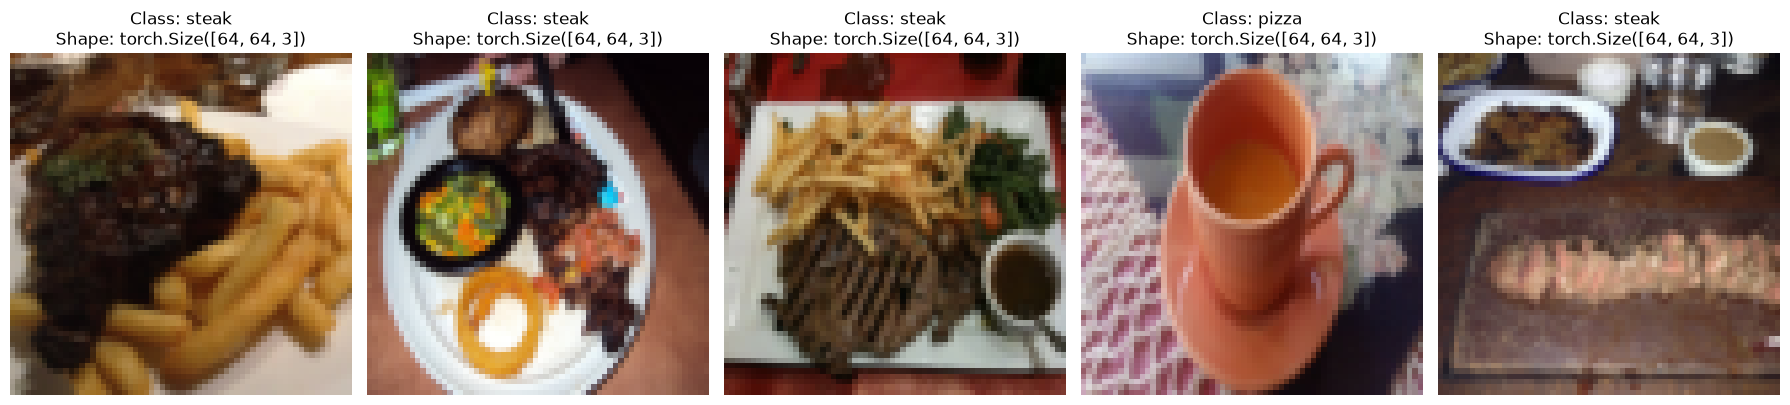

In [45]:
display_random_images(train_data,n=5,classes=class_names,seed=None)

For display purposes, n shouldn't be larger than 10. Setting to 10.


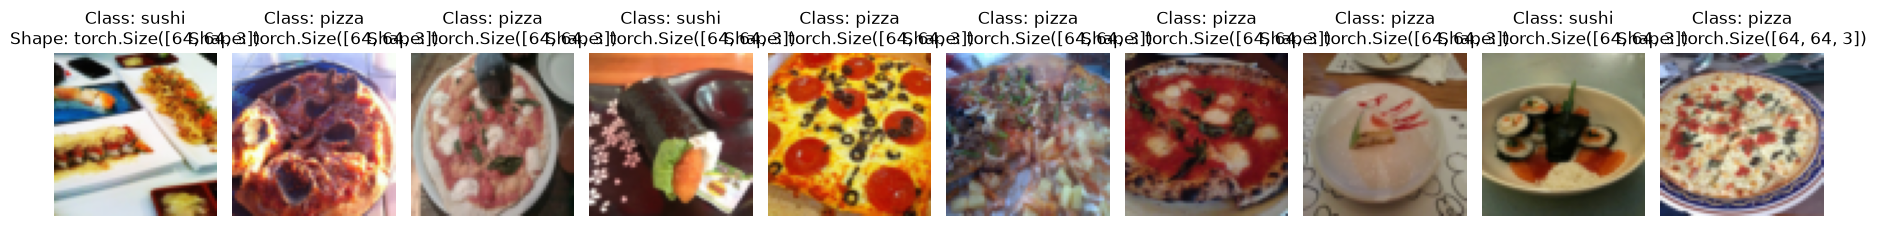

In [46]:
display_random_images(train_data,n=510,classes=class_names,seed=42)

In [47]:
from torch.utils.data import DataLoader
import os

BATCH_SIZE = 32
NUM_WORKERS = 0

train_dataloader_custom = DataLoader(
    dataset=train_data_custom,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=True
)

test_dataloader_custom = DataLoader(
    dataset=test_data_custom,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=False
)

images, labels = next(iter(train_dataloader_custom))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 64, 64])
torch.Size([32])
